# Read Data 

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

In [47]:
df_beton = pd.read_excel('Concrete_Data.xls')
df_beton

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.284354
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.178794
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.696601
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.768036


In [48]:
df_beton.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [49]:
df_beton.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [50]:
df_beton.columns = [
    'semen',
    'slag',
    'fly_ash',
    'air',
    'superplasticizer',
    'agregat_kasar',
    'agregat_halus',
    'umur',
    'kekuatan_beton'
    ]

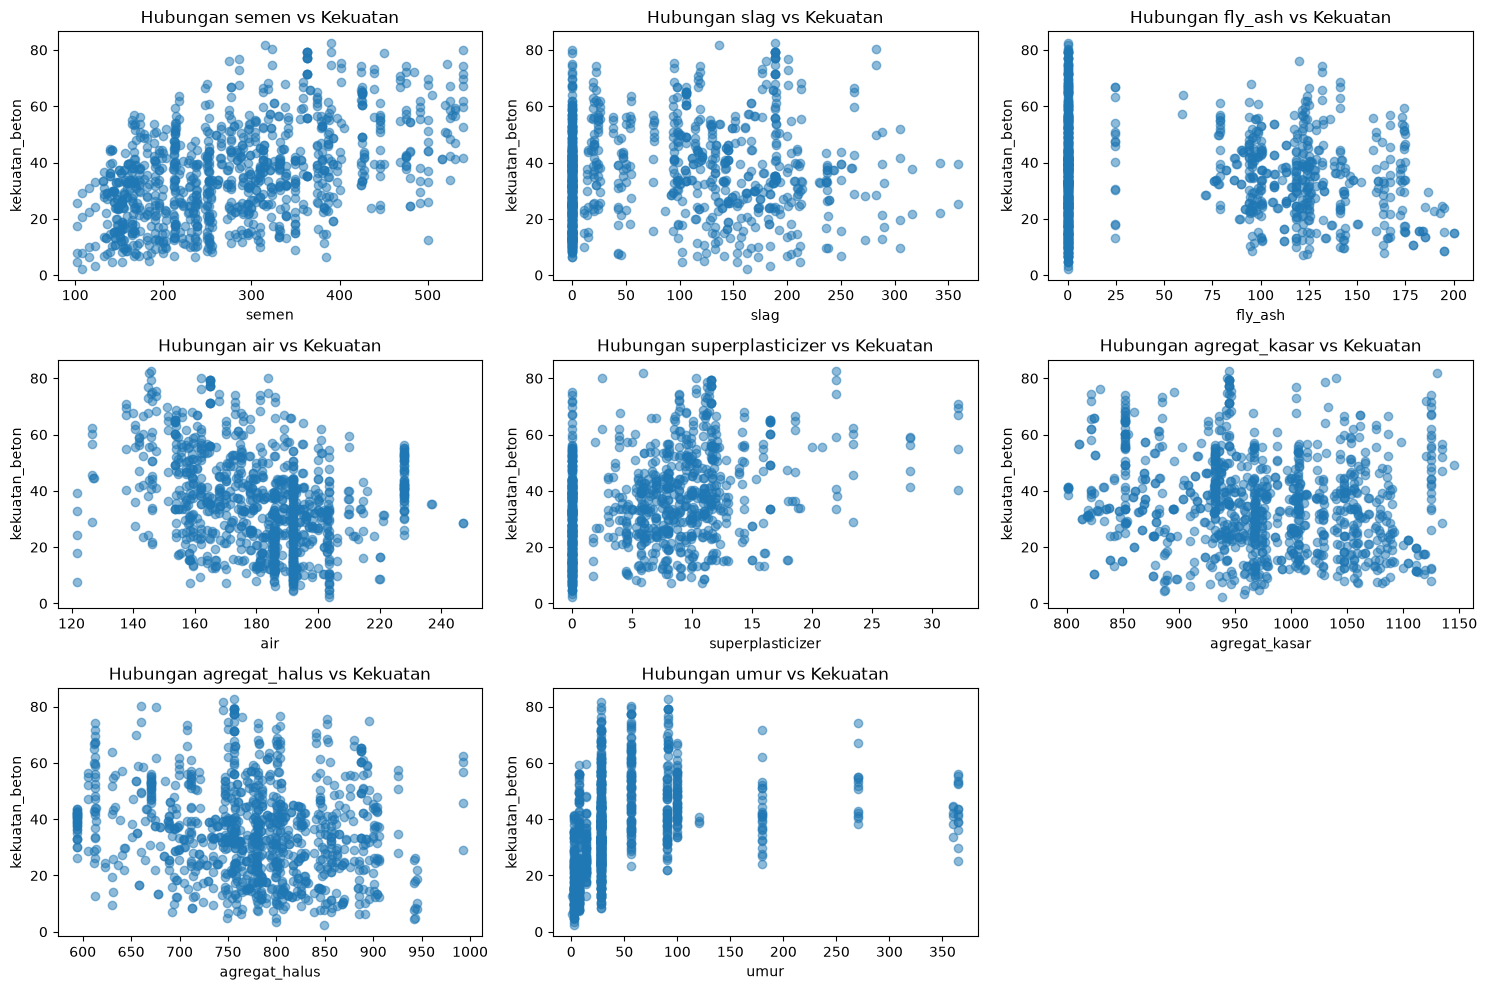

In [51]:
fitur = ['semen', 'slag', 'fly_ash', 'air', 'superplasticizer', 'agregat_kasar', 'agregat_halus', 'umur']
plt.figure(figsize=(15, 10))
for i, col in enumerate(fitur):
    plt.subplot(3, 3, i+1)
    plt.scatter(df_beton[col], df_beton['kekuatan_beton'], alpha=0.5)
    plt.xlabel(col)
    plt.ylabel('kekuatan_beton')
    plt.title(f'Hubungan {col} vs Kekuatan')

plt.tight_layout()
plt.show()

# Independent Dependent Variable

In [52]:
x = df_beton.iloc[:, 0:8].values  
y = df_beton.iloc[:, 8].values

# Split Test Train

In [53]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.25,random_state=0)

# Training Regresi - Estimasi

In [54]:
from sklearn.linear_model import LinearRegression

In [55]:
regresi = LinearRegression()

In [56]:
regresi.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[0.12,0.11,0.1 ,...,0.02,0.02,0.11]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-36.54
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[3153.53,2821.51,2366.49,..., 950.65, 241.84, 94.03]"


# Testing Regresi - Estimasi

In [57]:
y_estimasi = regresi.predict(x_test)

In [58]:
y_estimasi

array([39.53843768, 14.34936935, 61.32832879, 54.05007279, 24.44915798,
       53.61997349, 46.00051449, 27.31365368, 53.24118522, 37.08105655,
       16.76179008, 39.43023473, 29.6966645 , 35.88590096, 47.62603924,
       56.72190875, 35.78190854, 29.36761054, 48.69748598, 35.32244755,
       53.80778592, 32.10885773, 33.05096622, 48.24665201, 23.62225918,
       23.53937775, 69.39968359, 26.75217056, 56.71244997, 48.22144978,
       18.97357322, 36.44825335, 17.4285217 , 19.52169369, 24.61424879,
       15.28979022, 53.16913952, 28.15591384, 27.19467207, 26.31444139,
       52.52817644, 30.42589129, 25.77210551, 35.57602364, 53.79739874,
       53.99405466, 30.44610229, 44.14685805, 27.16218277, 57.07678358,
       36.70617404, 19.12163292, 23.21407155, 34.65583817, 43.69103509,
       47.45991463, 35.93732188, 53.14357884, 59.96760476, 36.64290334,
       31.15917378, 20.62564021, 50.82298208, 55.58817946, 20.68127714,
       44.27517256, 33.2676485 , 34.19515444, 19.361089  , 20.12

# Evaluasi Model 

In [59]:
from sklearn.metrics import mean_absolute_error, r2_score

In [60]:
print("MAE : ", mean_absolute_error(y_test, y_estimasi))
print("R2 : ",r2_score(y_test, y_estimasi))

MAE :  7.7814003049889
R2 :  0.6234144623633202


# Klasifikasi Data Baru 

In [62]:

data_baru = [[540.0, 0.0, 0.0, 162.0, 2.5, 1040.0, 676.0, 28]]

estimasi_baru = regresi.predict(data_baru)
print(estimasi_baru)

[52.86830908]


# Visualisasi Data

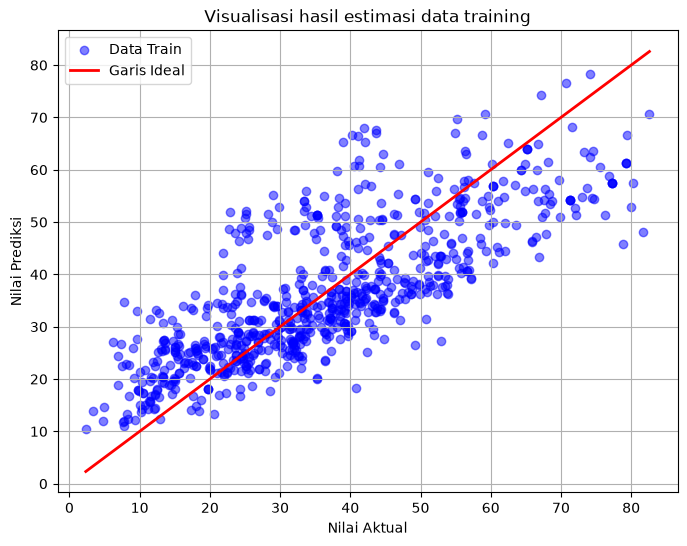

In [63]:
# Melakukan prediksi menggunakan data training
y_trainP = regresi.predict(x_train)

# Visualisasi hasil estimasi data training
plt.figure(figsize=(8, 6))
plt.title("Visualisasi hasil estimasi data training")

# Data observasi (Nilai Aktual vs Nilai Prediksi)
plt.scatter(y_train, y_trainP, c='blue', alpha=0.5, label='Data Train')

# Garis diagonal ideal (red line)
plt.plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], c='red', lw=2, label='Garis Ideal')

plt.xlabel('Nilai Aktual')
plt.ylabel('Nilai Prediksi')
plt.legend()
plt.grid(True)
plt.show()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_684\15969925.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


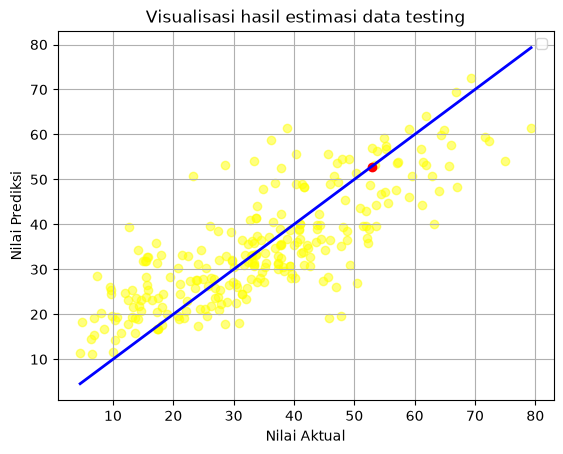

In [64]:
# melakukan prediksi menggunakan data testing
y_testP = regresi.predict(x_test)

# visualisai hasil estimasi data testing
plt.Figure(figsize=(8,6))
plt.title("Visualisasi hasil estimasi data testing")

# data observasi (data test) warna biru
plt.scatter(y_test, y_testP, c='yellow', alpha=0.5)

plt.scatter(estimasi_baru, estimasi_baru, c='red')

# data hasil estimasi dari data test
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], c='blue', lw=2)
plt.xlabel('Nilai Aktual')
plt.ylabel('Nilai Prediksi')
plt.legend()
plt.grid(True)
plt.show()

Kesimpulan 

Dataset  berisi 1.030 baris data campuran beton tanpa ada nilai yang hilang, dengan 9 variabel yang mencakup komposisi bahan baku, umur pengujian, dan kekuatan tekan beton. Secara umum, campuran beton dalam dataset ini menggunakan semen dengan rata-rata 281,17 kg/m³, air 181,57 kg/m³, serta agregat kasar dan halus berturut-turut sebesar 972,92 kg/m³ dan 773,58 kg/m³, di samping penggunaan bahan tambahan seperti slag, fly ash, dan superplasticizer. Pengujian dilakukan pada rentang umur beton 1 hingga 365 hari dengan median di umur standar 28 hari, menghasilkan variasi kekuatan tekan beton mulai dari yang terendah 2,33 MPa hingga tertinggi 82,60 MPa, serta rata-rata kekuatan sebesar 35,82 MPa.